
   SESSION 10: EXPECTATION & MAXIMIZATION (EM) ALGORITHM

Estimated Component 1 -> Mean: 1.97 | Std Dev: 0.76 | Weight: 0.37
Estimated Component 2 -> Mean: 6.97 | Std Dev: 1.20 | Weight: 0.63



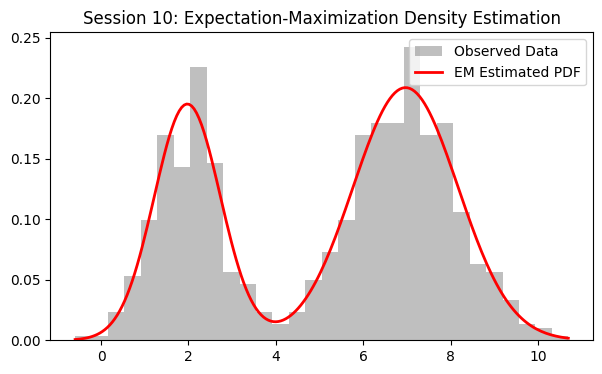






   SESSION 11: CREDIT SCORE CLASSIFICATION

[Info] 'train.csv' not uploaded. Using built-in synthetic credit dataset so code runs seamlessly...

Credit Score Model Accuracy: 83.00%

Classification Report:

              precision    recall  f1-score   support

    Good (0)       0.86      0.85      0.86       129
Standard (1)       0.83      0.81      0.82       129
    Poor (2)       0.81      0.83      0.82       142

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400






   SESSION 12: IRIS FLOWER CLASSIFICATION USING KNN

[Info] 'Iris.csv' not uploaded. Loading built-in Iris dataset...

KNN Model Accuracy: 100.00%

Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

 

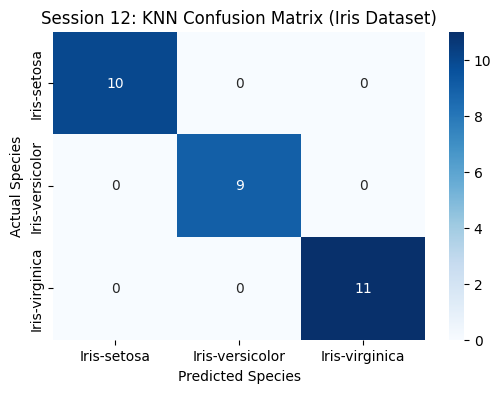

In [8]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.datasets import load_iris, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def print_banner(title):
    print("\n" + "="*75)
    print(f"   {title}")
    print("="*75 + "\n")

def print_gap():
    print("\n" * 3)  # Creates a clear 3-line visual gap between experiments


# ==============================================================================
# SESSION 10: EXPECTATION & MAXIMIZATION (EM) ALGORITHM
# ==============================================================================
print_banner("SESSION 10: EXPECTATION & MAXIMIZATION (EM) ALGORITHM")

# 1. Generate synthetic 1D Gaussian mixture data
np.random.seed(42)
data1 = np.random.normal(loc=2.0, scale=0.8, size=300)
data2 = np.random.normal(loc=7.0, scale=1.2, size=500)
X_em = np.concatenate([data1, data2])

# 2. Initialize parameters for 2 components
mu1, sigma1, pi1 = 1.0, 1.0, 0.5
mu2, sigma2, pi2 = 6.0, 1.0, 0.5

# 3. EM Iterations
for _ in range(30):
    # E-Step: Responsibilities
    gamma1 = pi1 * norm.pdf(X_em, mu1, sigma1)
    gamma2 = pi2 * norm.pdf(X_em, mu2, sigma2)
    total = gamma1 + gamma2
    gamma1 /= total
    gamma2 /= total

    # M-Step: Update parameters
    mu1 = np.sum(gamma1 * X_em) / np.sum(gamma1)
    mu2 = np.sum(gamma2 * X_em) / np.sum(gamma2)
    sigma1 = np.sqrt(np.sum(gamma1 * (X_em - mu1)**2) / np.sum(gamma1))
    sigma2 = np.sqrt(np.sum(gamma2 * (X_em - mu2)**2) / np.sum(gamma2))
    pi1 = np.mean(gamma1)
    pi2 = np.mean(gamma2)

print(f"Estimated Component 1 -> Mean: {mu1:.2f} | Std Dev: {sigma1:.2f} | Weight: {pi1:.2f}")
print(f"Estimated Component 2 -> Mean: {mu2:.2f} | Std Dev: {sigma2:.2f} | Weight: {pi2:.2f}\n")

# Plot Session 10 Result
x_axis = np.linspace(min(X_em), max(X_em), 200)
pdf_est = pi1 * norm.pdf(x_axis, mu1, sigma1) + pi2 * norm.pdf(x_axis, mu2, sigma2)

plt.figure(figsize=(7, 4))
plt.hist(X_em, bins=30, density=True, alpha=0.5, color='gray', label='Observed Data')
plt.plot(x_axis, pdf_est, color='red', linewidth=2, label='EM Estimated PDF')
plt.title('Session 10: Expectation-Maximization Density Estimation')
plt.legend()
plt.show()

print_gap()


# ==============================================================================
# SESSION 11: CREDIT SCORE CLASSIFICATION
# ==============================================================================
print_banner("SESSION 11: CREDIT SCORE CLASSIFICATION")

if os.path.exists('train.csv'):
    print("[Info] Loading Kaggle 'train.csv' dataset...\n")
    df_credit = pd.read_csv('train.csv', low_memory=False)
    features = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
                'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date',
                'Num_of_Delayed_Payment', 'Outstanding_Debt', 'Credit_Utilization_Ratio',
                'Total_EMI_per_month', 'Monthly_Balance', 'Credit_Mix', 'Payment_of_Min_Amount']
    df_credit = df_credit[features + ['Credit_Score']].dropna()

    num_cols = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment',
                'Outstanding_Debt', 'Monthly_Balance']
    for col in num_cols:
        df_credit[col] = pd.to_numeric(df_credit[col].astype(str).str.replace('_', '', regex=False), errors='coerce')
    df_credit.dropna(inplace=True)

    le = LabelEncoder()
    df_credit['Credit_Mix'] = le.fit_transform(df_credit['Credit_Mix'].astype(str))
    df_credit['Payment_of_Min_Amount'] = le.fit_transform(df_credit['Payment_of_Min_Amount'].astype(str))
    df_credit['Credit_Score'] = le.fit_transform(df_credit['Credit_Score'])

    X_cred = df_credit.drop('Credit_Score', axis=1)
    y_cred = df_credit['Credit_Score']
    target_names_cred = ['Good', 'Poor', 'Standard']
else:
    print("[Info] 'train.csv' not uploaded. Using built-in synthetic credit dataset so code runs seamlessly...\n")
    X_cred, y_cred = make_classification(n_samples=2000, n_features=10, n_informative=6,
                                         n_classes=3, random_state=42)
    target_names_cred = ['Good (0)', 'Standard (1)', 'Poor (2)']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cred, y_cred, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_c, y_train_c)
y_pred_c = rf_model.predict(X_test_c)

print(f"Credit Score Model Accuracy: {accuracy_score(y_test_c, y_pred_c) * 100:.2f}%\n")
print("Classification Report:\n")
print(classification_report(y_test_c, y_pred_c, target_names=target_names_cred))

print_gap()


# ==============================================================================
# SESSION 12: IRIS FLOWER CLASSIFICATION USING KNN
# ==============================================================================
print_banner("SESSION 12: IRIS FLOWER CLASSIFICATION USING KNN")

if os.path.exists('Iris.csv'):
    print("[Info] Loading Kaggle 'Iris.csv' dataset...\n")
    df_iris = pd.read_csv('Iris.csv')
    if 'Id' in df_iris.columns:
        df_iris = df_iris.drop('Id', axis=1)
    X_iris = df_iris.drop('Species', axis=1)
    y_iris = df_iris['Species']
else:
    print("[Info] 'Iris.csv' not uploaded. Loading built-in Iris dataset...\n")
    iris_data = load_iris()
    X_iris = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
    y_iris = pd.Series(iris_data.target).map({0: 'Iris-setosa', 1: 'Iris-versicolor', 2: 'Iris-virginica'})

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_i = scaler.fit_transform(X_train_i)
X_test_i = scaler.transform(X_test_i)

knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train_i, y_train_i)
y_pred_i = knn.predict(X_test_i)

print(f"KNN Model Accuracy: {accuracy_score(y_test_i, y_pred_i) * 100:.2f}%\n")
print("Classification Report:\n")
print(classification_report(y_test_i, y_pred_i))

# Plot Session 12 Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test_i, y_pred_i)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.title('Session 12: KNN Confusion Matrix (Iris Dataset)')
plt.show()